# Analisis Data Bike Sharing
- **Penyusun:** Toyo Wiyatno
- **Email:** toyo.pmc@gmail.com
- **ID Dicoding:** https://www.dicoding.com/users/toyowiyatno

## Rumusan Masalah Berbasis SMART
1. **Spesifik dan terukur:** Berapa rata-rata penyewaan sepeda harian pada setiap kategori kondisi cuaca selama 2011-2012?
2. **Berorientasi aksi dan terbatas waktu:** Bagaimana perbandingan proporsi penyewa casual dan registered pada hari kerja dengan akhir pekan/libur selama 2011-2012, dan strategi promosi apa yang sesuai dengan pola tersebut?

## Menyiapkan Pustaka Analisis

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print('Paket analisis siap digunakan.')

Paket analisis siap digunakan.


## Persiapan Data

### Mengumpulkan Data
Dataset harian dimuat dari berkas `day.csv`.

In [2]:
data_harian = pd.read_csv('data/day.csv')
data_harian.head()

,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,hum,windspeed,casual,registered,cnt
0,2011-01-01,3,0,1,0,5,0,1,0.190345,0.424774,0.359242,270,4110,2582
1,2011-01-02,4,0,1,0,6,1,1,0.773660,0.325191,0.450047,394,4023,2071
2,2011-01-03,1,0,1,0,0,1,1,0.293785,0.587556,0.416208,288,4035,4943
3,2011-01-04,3,0,1,0,1,1,1,0.482608,0.409034,0.156443,525,1459,5483
4,2011-01-05,3,0,1,0,2,1,1,0.216157,0.745849,0.318233,1076,977,2911


### Pemeriksaan Kualitas Data
Tahap ini memeriksa struktur kolom, nilai kosong, dan baris duplikat.

In [3]:
print('Struktur data:')
print('-' * 40)
data_harian.info()
print('-' * 40)
print('Jumlah nilai kosong tiap kolom:')
print(data_harian.isna().sum())
print('Jumlah baris duplikat:', data_harian.duplicated().sum())

Struktur data:
----------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 14 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   dteday      731 non-null    object 
 1   season      731 non-null    int64  
 2   yr          731 non-null    int64  
 3   mnth        731 non-null    int64  
 4   holiday     731 non-null    int64  
 5   weekday     731 non-null    int64  
 6   workingday  731 non-null    int64  
 7   weathersit  731 non-null    int64  
 8   temp        731 non-null    float64
 9   hum         731 non-null    float64
 10  windspeed   731 non-null    float64
 11  casual      731 non-null    int64  
 12  registered  731 non-null    int64  
 13  cnt         731 non-null    int64  
dtypes: float64(3), int64(10), object(1)
memory usage: 80.1+ KB
----------------------------------------
Jumlah nilai kosong tiap kolom:
dteday        0
season        0
yr            

**Temuan pemeriksaan data:**
1. Kolom `dteday` masih bertipe teks sehingga perlu diubah menjadi datetime.
2. Tidak ditemukan nilai kosong maupun baris duplikat.
3. Kolom `season` dan `weathersit` masih berupa kode angka; label kategori akan ditambahkan agar lebih mudah dibaca.

### Pembersihan Data
Tipe data tanggal diperbaiki dan label kategori ditambahkan.

In [4]:
data_harian['dteday'] = pd.to_datetime(data_harian['dteday'])

peta_musim = {1: 'Semi', 2: 'Panas', 3: 'Gugur', 4: 'Dingin'}
peta_cuaca = {1: 'Cerah/Berawan', 2: 'Mendung/Kabut', 3: 'Hujan/Salju Ringan', 4: 'Hujan Lebat'}

data_harian['musim'] = data_harian['season'].map(peta_musim)
data_harian['kondisi_cuaca'] = data_harian['weathersit'].map(peta_cuaca)
data_harian.head()

,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,hum,windspeed,casual,registered,cnt,musim,kondisi_cuaca
0,2011-01-01,3,0,1,0,5,0,1,0.190345,0.424774,0.359242,270,4110,2582,Gugur,Cerah/Berawan
1,2011-01-02,4,0,1,0,6,1,1,0.773660,0.325191,0.450047,394,4023,2071,Dingin,Cerah/Berawan
2,2011-01-03,1,0,1,0,0,1,1,0.293785,0.587556,0.416208,288,4035,4943,Semi,Cerah/Berawan
3,2011-01-04,3,0,1,0,1,1,1,0.482608,0.409034,0.156443,525,1459,5483,Gugur,Cerah/Berawan
4,2011-01-05,3,0,1,0,2,1,1,0.216157,0.745849,0.318233,1076,977,2911,Gugur,Cerah/Berawan


## Eksplorasi Data

### Eksplorasi 1: Ringkasan Penyewaan Menurut Kondisi Cuaca

In [5]:
tabel_cuaca = (
    data_harian.groupby('kondisi_cuaca')
    .agg(
        rata_rata=('cnt', 'mean'),
        maksimum=('cnt', 'max'),
        minimum=('cnt', 'min'),
        simpangan_baku=('cnt', 'std'),
    )
    .reset_index()
)
tabel_cuaca

,kondisi_cuaca,rata_rata,maksimum,minimum,simpangan_baku
0,Cerah/Berawan,3287.906818,5968,612,1600.185024
1,Hujan/Salju Ringan,3256.492308,5743,700,1491.277526
2,Mendung/Kabut,3415.584071,5935,628,1489.262115


### Eksplorasi 2: Perbandingan Penyewa Casual dan Registered Berdasarkan Jenis Hari

In [6]:
tabel_hari = (
    data_harian.groupby('workingday')
    .agg(
        casual_rata=('casual', 'mean'),
        registered_rata=('registered', 'mean'),
        total_rata=('cnt', 'mean'),
    )
    .reset_index()
)
tabel_hari['jenis_hari'] = tabel_hari['workingday'].map({0: 'Akhir Pekan/Libur', 1: 'Hari Kerja'})
tabel_hari

,workingday,casual_rata,registered_rata,total_rata,jenis_hari
0,0,750.192661,2549.743119,3282.775229,Akhir Pekan/Libur
1,1,844.986355,2497.081871,3342.354776,Hari Kerja


### Analisis Tambahan: Pengelompokan Suhu
Suhu dikelompokkan menjadi tiga kategori sederhana: Dingin, Sedang, dan Panas.

In [7]:
data_harian['kategori_suhu'] = pd.cut(
    data_harian['temp'],
    bins=[0, 0.3, 0.6, 1.0],
    labels=['Dingin', 'Sedang', 'Panas'],
)

ringkasan_suhu = (
    data_harian.groupby('kategori_suhu', observed=True)['cnt']
    .mean()
    .reset_index(name='rata_rata_penyewaan')
)
ringkasan_suhu

,kategori_suhu,rata_rata_penyewaan
0,Dingin,3161.261905
1,Sedang,3402.904412
2,Panas,3345.673540


## Visualisasi dan Analisis Penjelas

### Visualisasi 1: Rata-rata Penyewaan per Kondisi Cuaca

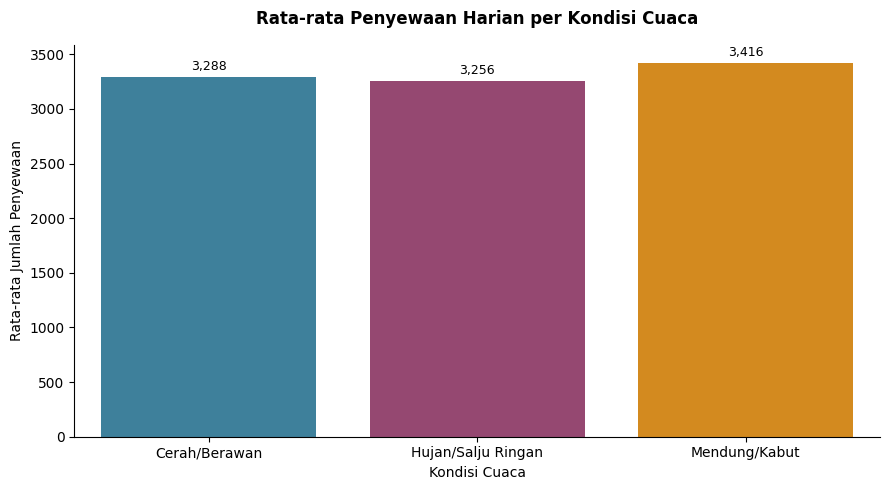

In [10]:
plt.figure(figsize=(9, 5))
warna_cuaca = ['#2E86AB', '#A23B72', '#F18F01']
ax = sns.barplot(
    data=data_harian,
    x='kondisi_cuaca',
    y='cnt',
    hue='kondisi_cuaca',
    palette=warna_cuaca,
    errorbar=None,
    legend=False,
)

plt.title('Rata-rata Penyewaan Harian per Kondisi Cuaca', fontsize=12, weight='bold', pad=15)
plt.xlabel('Kondisi Cuaca', fontsize=10)
plt.ylabel('Rata-rata Jumlah Penyewaan', fontsize=10)

for batang in ax.patches:
    tinggi = batang.get_height()
    ax.annotate(
        f'{tinggi:,.0f}',
        (batang.get_x() + batang.get_width() / 2, tinggi),
        ha='center',
        va='bottom',
        fontsize=9,
        xytext=(0, 3),
        textcoords='offset points',
    )

sns.despine()
plt.tight_layout()
plt.show()

### Visualisasi 2: Penyewa Casual dan Registered Menurut Jenis Hari

   workingday  casual_rata  registered_rata   total_rata         jenis_hari
0           0   750.192661      2549.743119  3282.775229  Akhir Pekan/Libur
1           1   844.986355      2497.081871  3342.354776         Hari Kerja
----------------------------------------------------------------------


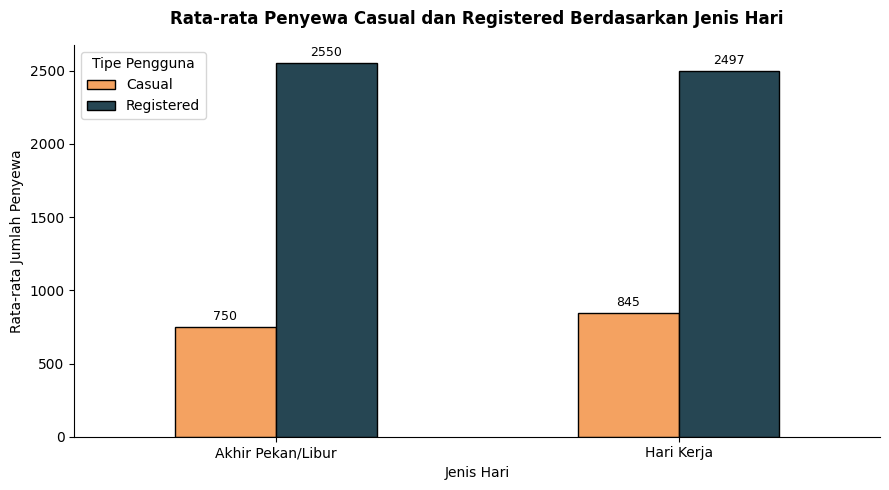

In [9]:
plot_hari = tabel_hari.set_index('jenis_hari')[['casual_rata', 'registered_rata']]
print(tabel_hari)
print('-' * 70)

ax = plot_hari.plot(
    kind='bar',
    figsize=(9, 5),
    color=['#F4A261', '#264653'],
    edgecolor='black',
)

plt.title('Rata-rata Penyewa Casual dan Registered Berdasarkan Jenis Hari', fontsize=12, weight='bold', pad=15)
plt.xlabel('Jenis Hari', fontsize=10)
plt.ylabel('Rata-rata Jumlah Penyewa', fontsize=10)
plt.xticks(rotation=0)

for wadah in ax.containers:
    ax.bar_label(wadah, fmt='%.0f', padding=3, fontsize=9)

plt.legend(['Casual', 'Registered'], title='Tipe Pengguna')
sns.despine()
plt.tight_layout()
plt.show()

## Kesimpulan dan Rekomendasi

### Kesimpulan
1. **Kondisi cuaca:** Rata-rata penyewaan harian tertinggi tercatat pada kondisi **Mendung/Kabut**, lalu **Cerah/Berawan**, dan terendah pada **Hujan/Salju Ringan**. Selisih antar kategori tidak terlalu besar, sehingga cuaca perlu dibaca bersama faktor lain seperti musim dan suhu.
2. **Tipe pengguna dan jenis hari:** Penyewa registered mendominasi rata-rata penyewaan pada hari kerja maupun akhir pekan/libur. Rata-rata penyewa casual sedikit lebih tinggi pada hari kerja, sedangkan registered sedikit lebih tinggi pada akhir pekan/libur.

### Rekomendasi
- **Konversi pengguna casual:** Tawarkan insentif pendaftaran anggota, misalnya potongan harga langganan atau poin loyalitas, terutama pada hari kerja ketika aktivitas casual relatif tinggi.
- **Program akhir pekan:** Siapkan paket rekreasi atau rute tematik untuk mempertahankan dan meningkatkan keterlibatan pengguna registered pada akhir pekan/libur.
- **Perawatan armada:** Jadwalkan pemeliharaan sepeda pada periode dengan prediksi cuaca buruk agar ketersediaan armada lebih optimal saat permintaan meningkat.